<!-- m6:proyecto -->
# Módulo 6 · Proyecto final integrador — Sistema de decisión para PagoYa
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · **grupal** · 40 pts del módulo

**Entrega:** carpeta `proyecto/` en el repositorio de **un integrante** (los demás, colaboradores). **Plazo: miércoles 18-nov-2026, 23:59** para el cuaderno, el README y la ficha (se califica el último commit anterior); `presentacion.pdf` hasta el jueves 19-nov, 18:00. **Defensa:** jueves 19-nov, 8 min + 3 min de preguntas.

| Archivo en `proyecto/` | Cómo se crea |
|---|---|
| `proyecto.ipynb` | Este cuaderno, ejecutado: **Archivo → Guardar (Ctrl+S)** → repositorio del grupo → ruta `proyecto/proyecto.ipynb` |
| `README.md` | Informe ejecutivo (1–2 páginas). Ya existe un `proyecto/README.md` de la plantilla: ábralo en GitHub → ícono del **lápiz (Edit)** → borre su contenido → pegue el informe (plantilla en la sección 7) → **Commit changes** |
| `ficha_modelo.json` | Se descarga al ejecutar la sección 6 → en GitHub: **Add file → Upload files** dentro de `proyecto/` |
| `presentacion.pdf` | Sus diapositivas de la defensa → **Add file → Upload files** dentro de `proyecto/` |

### Elija UN problema
| Problema | Datos (`curso.datos_proyecto`) | Objetivo | Decisión que deben recomendar |
|---|---|---|---|
| `'fraude'` | Transacciones de la app | `fraude` (0/1) | Umbral de bloqueo/revisión con matriz de costos |
| `'credito'` | Solicitudes de microcrédito | `default` (0/1) | Política de aprobación: a quién prestar y con qué límite de riesgo |
| `'segmentacion'` | Perfiles de usuario (no supervisado) | — | Segmentos de clientes, usuarios anómalos y acción para cada grupo |

### Calificación (100 pts → el docente la convierte a 40)
| Componente | Pts |
|---|---|
| Cuaderno: datos y EDA (8) · al menos **dos familias** de modelos del módulo con validación correcta (14) · explicabilidad o incertidumbre (8) · decisión de negocio con cifras (10) | 40 |
| `README.md`: informe ejecutivo para un comité | 12 |
| `ficha_modelo.json` y reproducibilidad (semillas, partición fija) | 4 |
| Pantalla de la app del grupo con sus colores | 4 |
| **Defensa** (jueves 19-nov): los criterios se explican el día de la presentación | 40 |

**Reutilice** el código de las clases 1–3 y del deber. Los datos son **propios de cada grupo** (dependen del nombre del grupo).

## 0. Preparación y datos del grupo

In [1]:
import importlib, subprocess, sys
for paquete in ['pymc']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
import os, urllib.request, warnings
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
print('Listo · curso', curso.VERSION)

Listo · curso m6-2026.11


In [2]:
GRUPO = 'Grupo 4'                                   # ✏️ nombre del grupo (el mismo del registro en el aula)
INTEGRANTES = ['Padilla Silva Darwin Medardo', 'Obando Castillo Juan Fernando']   # ✏️ apellidos y nombres
PROBLEMA = 'credito'                                # ✏️ 'fraude', 'credito' o 'segmentacion'
NOMBRE_APP, COLOR_PRINCIPAL, COLOR_ALERTA = 'PagoYa Crédito', '#1F4E78', '#C62828'   # ✏️ identidad de la app del grupo
df = curso.datos_proyecto(GRUPO, PROBLEMA)
df.head()

Huella de datos del proyecto: Grupo 4 · credito · semilla 96244
Solicitudes de microcrédito: 2500 · tasa de default 10.88%


,solicitud_id,edad,tipo_empleo,ingreso_mensual,antiguedad_meses,transacciones_mes,monto_credito,plazo_meses,cuota,ratio_cuota,mora_previa,default
0,CR-00000,53,independiente,1030.50,60,16,1880.0,12,184.87,0.1794,0,0
1,CR-00001,65,dependiente,976.69,6,11,2010.0,12,197.65,0.2024,0,0
2,CR-00002,26,dependiente,904.56,24,17,1980.0,12,194.70,0.2152,0,0
3,CR-00003,51,dependiente,1525.02,21,23,1230.0,24,69.70,0.0457,0,0
4,CR-00004,44,dependiente,1440.53,44,13,2310.0,12,227.15,0.1577,0,0


---
## 1. Datos y EDA (8 pts)
Diagnóstico de calidad (`curso.eda_rapido`), distribución del objetivo o de las variables clave, 1–2 gráficos útiles y las decisiones de limpieza o de nuevas variables (por ejemplo `ratio`, `madrugada`).

Filas: 2,500 · Columnas: 12

Dimensión del conjunto: (2500, 12)
Duplicados: 0

Valores nulos por columna:


,nulos
solicitud_id,0
edad,0
tipo_empleo,0
ingreso_mensual,0
antiguedad_meses,0
transacciones_mes,0
monto_credito,0
plazo_meses,0
cuota,0
ratio_cuota,0


Columna utilizada como monto del crédito: monto_credito

Tasa global de default: 10.88%


,n
default,
0,2228
1,272


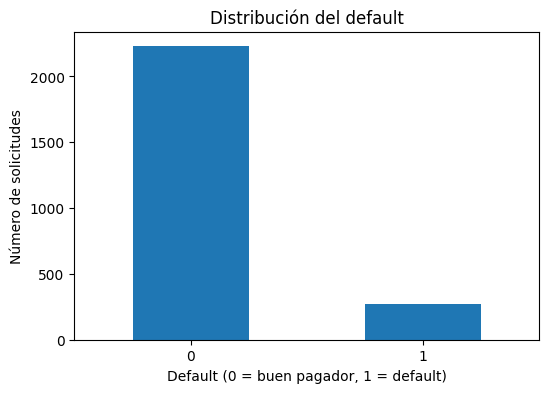

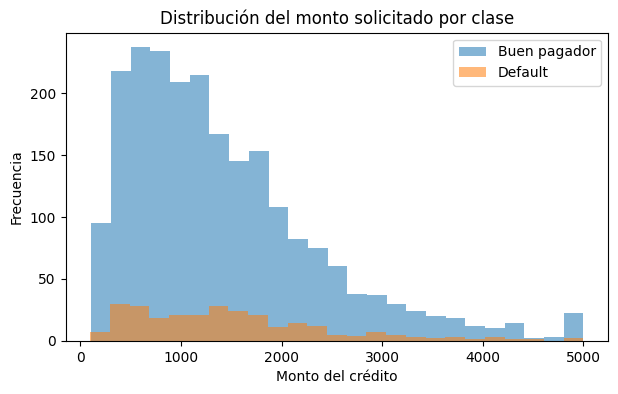


Default por quintil de monto/ingreso:


,n,tasa_default
quintil_ratio,,
"(0.297, 0.742]",500,0.108
"(0.742, 1.163]",500,0.068
"(1.163, 1.601]",500,0.100
"(1.601, 2.036]",500,0.102
"(2.036, 2.5]",500,0.166



Default por tipo de empleo:


,solicitudes,defaults,tasa_default
tipo_empleo,,,
informal,493,103,0.2089
independiente,751,66,0.0879
dependiente,1256,103,0.0820


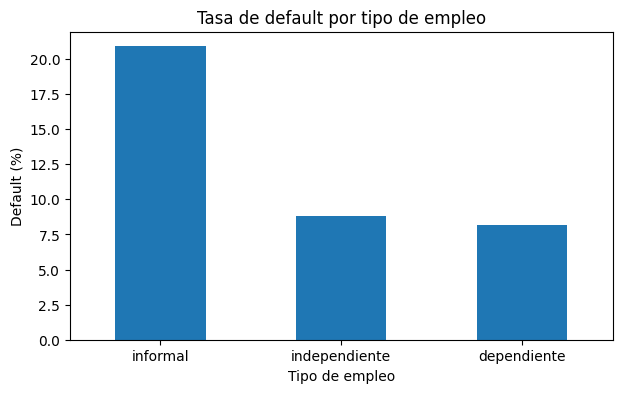

In [3]:
# ✏️ EDA

from IPython.display import display, Markdown, HTML

df = df.copy()

# Diagnóstico de calidad provisto por el curso.
curso.eda_rapido(df)

print('\nDimensión del conjunto:', df.shape)
print('Duplicados:', int(df.duplicated().sum()))
print('\nValores nulos por columna:')
display(df.isna().sum().to_frame('nulos').sort_values('nulos', ascending=False))

# Variable objetivo del problema de crédito.
TARGET = 'default'

# Identificamos automáticamente la columna que contiene el monto solicitado.
candidatos_monto = [
    'monto_credito', 'monto_solicitado', 'monto', 'credito',
    'valor_credito', 'monto_prestamo', 'prestamo'
]

MONTO_COL = next((c for c in candidatos_monto if c in df.columns), None)

if MONTO_COL is None:
    candidatos = [
        c for c in df.select_dtypes(include=np.number).columns
        if ('monto' in c.lower() or 'credito' in c.lower() or 'prestamo' in c.lower())
        and c != TARGET
    ]
    if candidatos:
        MONTO_COL = candidatos[0]

if MONTO_COL is None:
    raise ValueError(
        'No se encontró automáticamente la columna del monto del crédito. '
        'Revise df.columns y asigne MONTO_COL manualmente.'
    )

print('Columna utilizada como monto del crédito:', MONTO_COL)

# Nueva variable: relación monto solicitado / ingreso, cuando existe una variable de ingreso.
candidatos_ingreso = [
    'ingreso', 'ingreso_mensual', 'salario', 'ingresos',
    'ingreso_neto', 'renta'
]

INGRESO_COL = next((c for c in candidatos_ingreso if c in df.columns), None)

if INGRESO_COL is not None and 'ratio_monto_ingreso' not in df.columns:
    df['ratio_monto_ingreso'] = df[MONTO_COL] / df[INGRESO_COL].replace(0, np.nan)

# Reemplazo de infinitos que podrían aparecer al construir razones.
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Distribución del objetivo.
tasa_default = df[TARGET].mean()
print(f'\nTasa global de default: {tasa_default:.2%}')
display(df[TARGET].value_counts().rename_axis(TARGET).to_frame('n'))

plt.figure(figsize=(6, 4))
df[TARGET].value_counts().sort_index().plot(kind='bar')
plt.title('Distribución del default')
plt.xlabel('Default (0 = buen pagador, 1 = default)')
plt.ylabel('Número de solicitudes')
plt.xticks(rotation=0)
plt.show()

# Segundo gráfico útil: monto solicitado según resultado observado.
plt.figure(figsize=(7, 4))
for clase, etiqueta in [(0, 'Buen pagador'), (1, 'Default')]:
    valores = df.loc[df[TARGET] == clase, MONTO_COL].dropna()
    plt.hist(valores, bins=25, alpha=0.55, label=etiqueta)

plt.title('Distribución del monto solicitado por clase')
plt.xlabel('Monto del crédito')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()

# Tercer análisis: tasa de default por quintil de monto/ingreso.
if 'ratio_monto_ingreso' in df.columns:
    tmp = df[['ratio_monto_ingreso', TARGET]].dropna().copy()
    tmp['quintil_ratio'] = pd.qcut(tmp['ratio_monto_ingreso'], q=5, duplicates='drop')

    tabla_ratio = tmp.groupby('quintil_ratio', observed=False)[TARGET].agg(
        n='size',
        tasa_default='mean'
    )

    print('\nDefault por quintil de monto/ingreso:')
    display(tabla_ratio.round(4))

# Análisis de la variable categórica tipo_empleo.
if 'tipo_empleo' in df.columns:
    tabla_empleo = df.groupby('tipo_empleo', observed=False)[TARGET].agg(
        solicitudes='size',
        defaults='sum',
        tasa_default='mean'
    ).sort_values('tasa_default', ascending=False)

    print('\nDefault por tipo de empleo:')
    display(tabla_empleo.round(4))

    plt.figure(figsize=(7, 4))
    (tabla_empleo['tasa_default'] * 100).plot(kind='bar')
    plt.title('Tasa de default por tipo de empleo')
    plt.xlabel('Tipo de empleo')
    plt.ylabel('Default (%)')
    plt.xticks(rotation=0)
    plt.show()

**✍️ Hallazgos del EDA:** _(3–5 líneas)_

El conjunto contiene 2.500 solicitudes, con una tasa de default de 10,88 %, sin registros duplicados ni valores nulos.El monto solicitado presenta una superposición considerable entre buenos pagadores y clientes con incumplimiento. En cambio, el quintil más alto de ratio_monto_ingreso alcanza una tasa de default de 16,6 %, superior al promedio general.La variable tipo_empleo muestra diferencias importantes: los clientes con empleo informal presentan 20,89 % de default, frente a 8,79 % en independientes y 8,20 % en dependientes. Por ello, tipo_empleo fue incorporada al modelado mediante One-Hot Encoding.

---
## 2. Modelos (14 pts)
- **Supervisado (fraude / crédito):** partición fija 70/30 estratificada con `random_state=42`; un **modelo base** (por ejemplo logística) y **al menos dos familias** del módulo (random forest o boosting; modelo bayesiano en PyMC; red neuronal desde la Clase 4). Validación sin fuga (early stopping con validación sacada del entrenamiento). Métricas: AUC, exactitud balanceada y Brier.
- **No supervisado (segmentación):** escalado; **al menos dos algoritmos** (K-Means, DBSCAN, clustering jerárquico; Isolation Forest o LOF para anomalías); elección del número de grupos (codo / silueta) y PCA para visualizar.

In [4]:
# ✏️ Modelos y tabla comparativa

import importlib, subprocess, sys

# XGBoost se utiliza como familia de boosting.
if importlib.util.find_spec('xgboost') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'xgboost'])

import pymc as pm
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, brier_score_loss
from xgboost import XGBClassifier

# Solo se usan variables disponibles antes de tomar la decisión de crédito.
# Se eliminan identificadores y la variable objetivo.
excluir = {TARGET}

for c in df.columns:
    nombre = c.lower()
    if (
        nombre == TARGET
        or nombre.startswith('id_')
        or nombre.endswith('_id')
        or nombre in {'id', 'codigo', 'solicitud', 'cliente'}
    ):
        excluir.add(c)

# Variables numéricas.
features_numericas = [
    c for c in df.select_dtypes(include=[np.number, 'bool']).columns
    if c not in excluir
]

if TARGET in features_numericas:
    features_numericas.remove(TARGET)

# Variables categóricas.
features_categoricas = []

if 'tipo_empleo' in df.columns:
    features_categoricas.append('tipo_empleo')

features_originales = features_numericas + features_categoricas

print('Variables numéricas:', features_numericas)
print('Variables categóricas:', features_categoricas)

X = df[features_originales].copy()
y = df[TARGET].astype(int).copy()

# Partición fija 70/30 estratificada, como exige el proyecto.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

# Validación separada exclusivamente del entrenamiento.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

print('Entrenamiento:', X_fit.shape)
print('Validación:', X_val.shape)
print('Prueba:', X_test.shape)

# Imputación y escalado de variables numéricas.
pipeline_numerico = Pipeline([
    ('imputador', SimpleImputer(strategy='median')),
    ('escalador', StandardScaler())
])

# Imputación y One-Hot Encoding de tipo_empleo.
pipeline_categorico = Pipeline([
    ('imputador', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(
        drop='first',
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# El preprocesamiento se aprende únicamente del subconjunto de entrenamiento.
preprocesador = ColumnTransformer([
    ('num', pipeline_numerico, features_numericas),
    ('cat', pipeline_categorico, features_categoricas)
], remainder='drop', verbose_feature_names_out=False)

X_fit_proc = preprocesador.fit_transform(X_fit)
X_val_proc = preprocesador.transform(X_val)
X_test_proc = preprocesador.transform(X_test)

# Nombres de las variables después del preprocesamiento.
features_modelo = preprocesador.get_feature_names_out().tolist()

print('\nVariables utilizadas por los modelos:')
print(features_modelo)

# Categoría de referencia de tipo_empleo.
categoria_referencia = None

if features_categoricas:
    encoder = preprocesador.named_transformers_['cat'].named_steps['onehot']
    categorias_empleo = encoder.categories_[0].tolist()
    indice_referencia = int(encoder.drop_idx_[0])
    categoria_referencia = categorias_empleo[indice_referencia]

    print('Categorías de tipo_empleo:', categorias_empleo)
    print('Categoría de referencia:', categoria_referencia)

# ---------------------------------------------------------
# 1) Modelo base: Regresión Logística
# ---------------------------------------------------------

modelo_log = LogisticRegression(
    max_iter=2000,
    class_weight='balanced',
    random_state=42
)

modelo_log.fit(X_fit_proc, y_fit)

p_log_val = modelo_log.predict_proba(X_val_proc)[:, 1]
p_log_test = modelo_log.predict_proba(X_test_proc)[:, 1]

# ---------------------------------------------------------
# 2) Segunda familia: XGBoost con early stopping
# ---------------------------------------------------------

peso_clase = (y_fit == 0).sum() / max((y_fit == 1).sum(), 1)

modelo_xgb = XGBClassifier(
    n_estimators=1500,
    learning_rate=0.03,
    max_depth=3,
    min_child_weight=2,
    subsample=0.90,
    colsample_bytree=0.90,
    reg_lambda=1.0,
    scale_pos_weight=peso_clase,
    eval_metric='logloss',
    early_stopping_rounds=40,
    random_state=42,
    n_jobs=-1
)

modelo_xgb.fit(
    X_fit_proc,
    y_fit,
    eval_set=[(X_val_proc, y_val)],
    verbose=False
)

p_xgb_val = modelo_xgb.predict_proba(X_val_proc)[:, 1]
p_xgb_test = modelo_xgb.predict_proba(X_test_proc)[:, 1]

# ---------------------------------------------------------
# 3) Tercera familia: Regresión Logística Bayesiana en PyMC
# ---------------------------------------------------------

with pm.Model() as modelo_bayes:
    a = pm.Normal('a', mu=0, sigma=2.5)
    b = pm.Normal('b', mu=0, sigma=1, shape=len(features_modelo))

    eta = a + pm.math.dot(X_fit_proc, b)
    p = pm.math.sigmoid(eta)

    pm.Bernoulli(
        'y_obs',
        p=p,
        observed=y_fit.to_numpy()
    )

    tr_bayes = pm.sample(
        1000,
        tune=1000,
        chains=4,
        target_accept=0.95,
        random_seed=42,
        progressbar=False
    )

# Probabilidades posteriores medias.
a_post = tr_bayes.posterior['a'].stack(muestra=('chain', 'draw')).values

b_post = (
    tr_bayes.posterior['b']
    .stack(muestra=('chain', 'draw'))
    .transpose('b_dim_0', 'muestra')
    .values
)

def prob_bayes_media(X_proc):
    logits = a_post[:, None] + b_post.T @ np.asarray(X_proc).T
    return (1 / (1 + np.exp(-logits))).mean(axis=0)

p_bayes_val = prob_bayes_media(X_val_proc)
p_bayes_test = prob_bayes_media(X_test_proc)

# Predicciones de validación.
probs_val = {
    'Logística': p_log_val,
    'XGBoost': p_xgb_val,
    'Bayes logístico': p_bayes_val
}

# Predicciones de prueba.
probs_test = {
    'Logística': p_log_test,
    'XGBoost': p_xgb_test,
    'Bayes logístico': p_bayes_test
}

# Comparación en PRUEBA.
filas = []

for nombre, prob in probs_test.items():
    filas.append({
        'Modelo': nombre,
        'AUC': roc_auc_score(y_test, prob),
        'Exactitud_balanceada': balanced_accuracy_score(y_test, prob >= 0.5),
        'Brier': brier_score_loss(y_test, prob)
    })

tabla_metricas = (
    pd.DataFrame(filas)
    .set_index('Modelo')
    .sort_values(['AUC', 'Brier'], ascending=[False, True])
)

display(tabla_metricas.round(4))

# La elección del modelo se realiza con VALIDACIÓN, no con el conjunto de prueba.
auc_validacion = {
    nombre: roc_auc_score(y_val, prob)
    for nombre, prob in probs_val.items()
}

MODELO_ELEGIDO = max(auc_validacion, key=auc_validacion.get)

print('\nAUC de validación:')
display(pd.Series(auc_validacion, name='AUC_validacion').sort_values(ascending=False).round(4))
print('Modelo elegido:', MODELO_ELEGIDO)
print('Mejor iteración de XGBoost:', getattr(modelo_xgb, 'best_iteration', None))

Variables numéricas: ['edad', 'ingreso_mensual', 'antiguedad_meses', 'transacciones_mes', 'monto_credito', 'plazo_meses', 'cuota', 'ratio_cuota', 'mora_previa', 'ratio_monto_ingreso']
Variables categóricas: ['tipo_empleo']
Entrenamiento: (1400, 11)
Validación: (350, 11)
Prueba: (750, 11)

Variables utilizadas por los modelos:
['edad', 'ingreso_mensual', 'antiguedad_meses', 'transacciones_mes', 'monto_credito', 'plazo_meses', 'cuota', 'ratio_cuota', 'mora_previa', 'ratio_monto_ingreso', 'tipo_empleo_independiente', 'tipo_empleo_informal']
Categorías de tipo_empleo: ['dependiente', 'independiente', 'informal']
Categoría de referencia: dependiente


,AUC,Exactitud_balanceada,Brier
Modelo,,,
Logística,0.7395,0.7065,0.1768
Bayes logístico,0.7371,0.5458,0.0870
XGBoost,0.6809,0.5633,0.1168



AUC de validación:


,AUC_validacion
Logística,0.7418
Bayes logístico,0.7415
XGBoost,0.6942


Modelo elegido: Logística
Mejor iteración de XGBoost: 1078


**✍️ Comparación y elección del modelo:** _(¿cuál y por qué?)_

Se compararon regresión logística, XGBoost y regresión logística bayesiana. La regresión logística fue seleccionada porque obtuvo el mayor AUC en validación (0,7418), ligeramente superior al modelo bayesiano (0,7415) y a XGBoost (0,6942).

En el conjunto de prueba, la regresión logística obtuvo un AUC de 0,7395, una exactitud balanceada de 0,7065 y un Brier de 0,1768. Aunque el modelo bayesiano presentó un Brier menor (0,0870), la selección se mantuvo con el criterio definido previamente de mayor AUC en validación, evitando utilizar el conjunto de prueba para escoger el modelo.

La variable categórica tipo_empleo fue incorporada mediante One-Hot Encoding, utilizando dependiente como categoría de referencia.

---
## 3. Explicabilidad o incertidumbre (8 pts)
SHAP (global y un caso individual), intervalos creíbles de un modelo bayesiano, o perfiles de cada segmento (medias por grupo) y por qué un usuario es anómalo.

,Variable,Coef_media,IC90_inf,IC90_sup,Odds_ratio
11,tipo_empleo_informal,1.4890,1.1397,1.8425,4.4326
7,ratio_cuota,0.8906,0.3969,1.3791,2.4367
8,mora_previa,0.6194,0.5004,0.7364,1.8578
2,antiguedad_meses,-0.4434,-0.6026,-0.2867,0.6418
5,plazo_meses,0.4365,0.1929,0.6742,1.5474
9,ratio_monto_ingreso,-0.3330,-0.8461,0.1728,0.7168
0,edad,-0.2783,-0.4373,-0.1182,0.7570
10,tipo_empleo_independiente,0.0773,-0.3255,0.4725,1.0804
1,ingreso_mensual,-0.0642,-0.4758,0.3328,0.9378
3,transacciones_mes,-0.0460,-0.1987,0.1114,0.9550


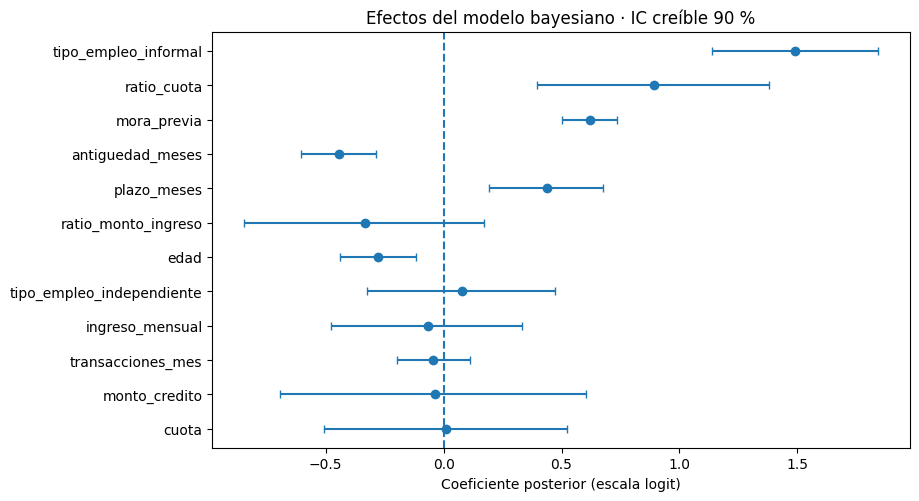

Variables con IC90 que no cruza cero:


,Variable,Coef_media,IC90_inf,IC90_sup,Odds_ratio
11,tipo_empleo_informal,1.4890,1.1397,1.8425,4.4326
7,ratio_cuota,0.8906,0.3969,1.3791,2.4367
8,mora_previa,0.6194,0.5004,0.7364,1.8578
2,antiguedad_meses,-0.4434,-0.6026,-0.2867,0.6418
5,plazo_meses,0.4365,0.1929,0.6742,1.5474
0,edad,-0.2783,-0.4373,-0.1182,0.7570



Efectos de tipo_empleo:


,Variable,Coef_media,IC90_inf,IC90_sup,Odds_ratio
11,tipo_empleo_informal,1.4890,1.1397,1.8425,4.4326
10,tipo_empleo_independiente,0.0773,-0.3255,0.4725,1.0804


Categoría de referencia: dependiente



**Lectura:** la variable con mayor efecto posterior en valor absoluto es **`tipo_empleo_informal`**.

Su coeficiente medio es **1.489** y su odds ratio es **4.433**. La categoría **informal**, comparada con **dependiente**, **aumenta** las odds de default, manteniendo constantes las demás variables.


In [5]:
# ✏️ Explicabilidad / incertidumbre

# Se utilizan los intervalos creíbles de la regresión bayesiana.
coef_media = b_post.mean(axis=1)
coef_inf = np.quantile(b_post, 0.05, axis=1)
coef_sup = np.quantile(b_post, 0.95, axis=1)

tabla_bayes = pd.DataFrame({
    'Variable': features_modelo,
    'Coef_media': coef_media,
    'IC90_inf': coef_inf,
    'IC90_sup': coef_sup,
    'Odds_ratio': np.exp(coef_media)
}).sort_values('Coef_media', key=lambda s: np.abs(s), ascending=False)

display(tabla_bayes.round(4))

# Gráfico de los coeficientes con intervalo creíble del 90 %.
orden = tabla_bayes.iloc[::-1].reset_index(drop=True)

plt.figure(figsize=(9, max(4, len(orden) * 0.45)))
ypos = np.arange(len(orden))

plt.errorbar(
    orden['Coef_media'],
    ypos,
    xerr=[
        orden['Coef_media'] - orden['IC90_inf'],
        orden['IC90_sup'] - orden['Coef_media']
    ],
    fmt='o',
    capsize=3
)

plt.axvline(0, linestyle='--')
plt.yticks(ypos, orden['Variable'])
plt.xlabel('Coeficiente posterior (escala logit)')
plt.title('Efectos del modelo bayesiano · IC creíble 90 %')
plt.show()

# Variables cuyo intervalo creíble no cruza cero.
efectos_claros = tabla_bayes[
    (tabla_bayes['IC90_inf'] > 0) | (tabla_bayes['IC90_sup'] < 0)
]

print('Variables con IC90 que no cruza cero:')
display(efectos_claros.round(4))

# Efectos correspondientes a tipo_empleo.
efecto_empleo = tabla_bayes[
    tabla_bayes['Variable'].str.startswith('tipo_empleo_')
]

print('\nEfectos de tipo_empleo:')
display(efecto_empleo.round(4))
print('Categoría de referencia:', categoria_referencia)

if len(efectos_claros):
    principal = efectos_claros.iloc[0]
else:
    principal = tabla_bayes.iloc[0]

direccion = 'aumenta' if principal['Coef_media'] > 0 else 'reduce'
variable_principal = principal['Variable']

if variable_principal.startswith('tipo_empleo_'):
    categoria = variable_principal.replace('tipo_empleo_', '')

    display(Markdown(f'''
**Lectura:** la variable con mayor efecto posterior en valor absoluto es **`{variable_principal}`**.

Su coeficiente medio es **{principal["Coef_media"]:.3f}** y su odds ratio es **{principal["Odds_ratio"]:.3f}**. La categoría **{categoria}**, comparada con **{categoria_referencia}**, **{direccion}** las odds de default, manteniendo constantes las demás variables.
'''))
else:
    display(Markdown(f'''
**Lectura:** la variable con mayor efecto posterior en valor absoluto es **`{variable_principal}`**.

Su coeficiente medio es **{principal["Coef_media"]:.3f}** y su odds ratio es **{principal["Odds_ratio"]:.3f}**. Como las variables numéricas fueron estandarizadas, un aumento de una desviación estándar en esta variable **{direccion}** las odds de default, manteniendo constantes las demás variables.
'''))

---
## 4. Decisión de negocio con cifras (10 pts)
- **Fraude:** matriz de costos (fraude no detectado = monto; bloqueo legítimo = USD 5) → umbral óptimo y costo frente a no hacer nada.
- **Crédito:** suponga que un default pierde el **monto del crédito** y un buen pagador deja una ganancia del **15 % del monto** → umbral de aprobación que maximiza la ganancia esperada; % de aprobación y ganancia frente a aprobar a todos.
- **Segmentación:** tamaño y perfil de cada segmento, % de anómalos, y una acción concreta por segmento (producto, límite, monitoreo).

Umbral óptimo seleccionado en VALIDACIÓN: 0.46
Ganancia de validación: 32931.5
Tasa de aprobación en validación: 68.57%


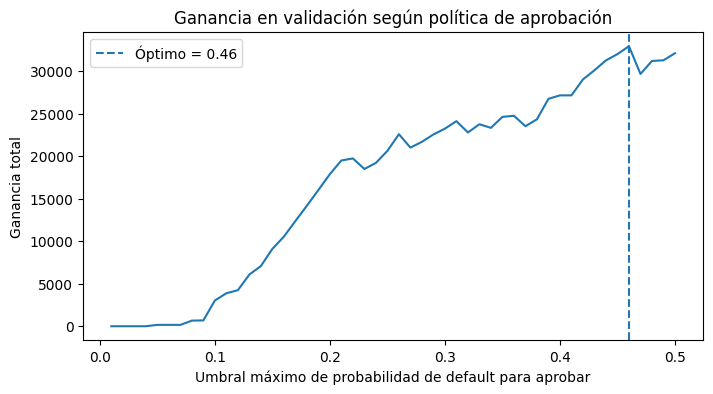

,Política,Ganancia_test,Tasa_aprobacion,Defaults_aprobados
0,Modelo + umbral óptimo,62393.0,0.6693,28
1,Aprobar a todos,12814.0,1.0000,82
2,No aprobar a nadie,0.0,0.0000,0


Umbral teórico de equilibrio: 13.04%
Mejora frente a aprobar a todos: USD 49579.0


In [6]:
# ✏️ Decisión y cifras

# El proyecto define:
# - si se aprueba y ocurre default: pérdida = 100 % del monto;
# - si se aprueba y es buen pagador: ganancia = 15 % del monto;
# - si se rechaza: ganancia/pérdida = 0.
#
# El umbral se elige en VALIDACIÓN y se reporta el resultado final en TEST.

# Monto asociado a cada partición, respetando los índices originales.
monto_val = df.loc[X_val.index, MONTO_COL].to_numpy(dtype=float)
monto_test = df.loc[X_test.index, MONTO_COL].to_numpy(dtype=float)

y_val_np = y_val.to_numpy()
y_test_np = y_test.to_numpy()

p_val_elegido = probs_val[MODELO_ELEGIDO]
p_test_elegido = probs_test[MODELO_ELEGIDO]

def ganancia_credito(y_real, prob_default, monto, umbral):
    # Aprobar si el riesgo estimado de default no supera el umbral.
    aprobar = np.asarray(prob_default) <= umbral
    y_real = np.asarray(y_real)
    monto = np.asarray(monto, dtype=float)

    ganancia = np.where(
        aprobar & (y_real == 0),
        0.15 * monto,
        np.where(aprobar & (y_real == 1), -monto, 0.0)
    )

    return {
        'ganancia': float(ganancia.sum()),
        'aprobados': int(aprobar.sum()),
        'tasa_aprobacion': float(aprobar.mean()),
        'defaults_aprobados': int(((y_real == 1) & aprobar).sum())
    }

# Búsqueda del umbral de riesgo en VALIDACIÓN.
umbrales = np.arange(0.01, 0.501, 0.01)

resultados_val = []

for u in umbrales:
    r = ganancia_credito(
        y_val_np,
        p_val_elegido,
        monto_val,
        u
    )

    resultados_val.append({
        'umbral': u,
        **r
    })

tabla_umbrales = pd.DataFrame(resultados_val)

fila_optima = tabla_umbrales.loc[
    tabla_umbrales['ganancia'].idxmax()
]

UMBRAL_OPTIMO = float(fila_optima['umbral'])

print('Umbral óptimo seleccionado en VALIDACIÓN:', round(UMBRAL_OPTIMO, 3))
print('Ganancia de validación:', round(float(fila_optima['ganancia']), 2))
print('Tasa de aprobación en validación:', f"{fila_optima['tasa_aprobacion']:.2%}")

plt.figure(figsize=(8, 4))
plt.plot(tabla_umbrales['umbral'], tabla_umbrales['ganancia'])
plt.axvline(UMBRAL_OPTIMO, linestyle='--', label=f'Óptimo = {UMBRAL_OPTIMO:.2f}')
plt.xlabel('Umbral máximo de probabilidad de default para aprobar')
plt.ylabel('Ganancia total')
plt.title('Ganancia en validación según política de aprobación')
plt.legend()
plt.show()

# Evaluación FINAL en TEST con el umbral ya fijado.
resultado_optimo = ganancia_credito(
    y_test_np,
    p_test_elegido,
    monto_test,
    UMBRAL_OPTIMO
)

# Política de referencia: aprobar a todos.
resultado_todos = ganancia_credito(
    y_test_np,
    p_test_elegido,
    monto_test,
    1.0
)

# Política de referencia: no aprobar a nadie.
resultado_nadie = ganancia_credito(
    y_test_np,
    p_test_elegido,
    monto_test,
    -1.0
)

GANANCIA_OPTIMA = resultado_optimo['ganancia']
GANANCIA_TODOS = resultado_todos['ganancia']
TASA_APROBACION = resultado_optimo['tasa_aprobacion']
NUM_APROBADOS = resultado_optimo['aprobados']
MEJORA_GANANCIA = GANANCIA_OPTIMA - GANANCIA_TODOS

# Umbral teórico de equilibrio si solo se considera el valor esperado:
# 0.15*(1-p) - 1*p > 0  =>  p < 0.15/1.15 ≈ 13.04 %
UMBRAL_TEORICO = 0.15 / 1.15

tabla_negocio = pd.DataFrame({
    'Política': ['Modelo + umbral óptimo', 'Aprobar a todos', 'No aprobar a nadie'],
    'Ganancia_test': [
        GANANCIA_OPTIMA,
        GANANCIA_TODOS,
        resultado_nadie['ganancia']
    ],
    'Tasa_aprobacion': [
        TASA_APROBACION,
        resultado_todos['tasa_aprobacion'],
        resultado_nadie['tasa_aprobacion']
    ],
    'Defaults_aprobados': [
        resultado_optimo['defaults_aprobados'],
        resultado_todos['defaults_aprobados'],
        resultado_nadie['defaults_aprobados']
    ]
})

display(tabla_negocio.round({
    'Ganancia_test': 2,
    'Tasa_aprobacion': 4
}))

print('Umbral teórico de equilibrio:', f'{UMBRAL_TEORICO:.2%}')
print('Mejora frente a aprobar a todos: USD', round(MEJORA_GANANCIA, 2))

**✍️ Recomendación:** _(con cifras)_

Se recomienda aprobar las solicitudes cuyo **score de riesgo estimado por el modelo** sea igual o inferior al 46 %, umbral que maximizó la ganancia en el conjunto de validación.

Al aplicar esta política al conjunto de prueba se aprobarían 502 de las 750 solicitudes, equivalentes al 66,93 %, con 28 defaults aprobados y una ganancia estimada de USD 62.393,00.

En comparación, aprobar todas las solicitudes habría generado una ganancia de únicamente USD 12.814,00. Por lo tanto, la política basada en el modelo incrementa la ganancia estimada en USD 49.579,00, al reducir la exposición a solicitudes de mayor riesgo.

---
## 5. Pantalla de la app del grupo (4 pts)
Muestre un caso real de sus datos con `curso.pantalla_resultado(...)` (o una pantalla propia). Ejemplo: `curso.pantalla_resultado(NOMBRE_APP, COLOR_PRINCIPAL, COLOR_ALERTA, 'Solicitud CR-00012', ['Ingreso: USD 850', 'Monto: USD 1 200'], probs=probs)`

In [7]:
# ✏️ Pantalla de la app

# Se muestra una solicitud real del conjunto de prueba cercana al umbral de decisión.
distancia_umbral = np.abs(p_test_elegido - UMBRAL_OPTIMO)
pos = int(np.argmin(distancia_umbral))
idx_caso = X_test.index[pos]

p_caso = float(p_test_elegido[pos])
monto_caso = float(df.loc[idx_caso, MONTO_COL])
decision_caso = 'APROBAR' if p_caso <= UMBRAL_OPTIMO else 'REVISAR / RECHAZAR'
color_decision = COLOR_PRINCIPAL if p_caso <= UMBRAL_OPTIMO else COLOR_ALERTA

# Información adicional disponible para presentar.
detalles = [
    f'Monto solicitado: USD {monto_caso:,.2f}',
    f'Score de riesgo estimado: {p_caso:.2%}',
    f'Límite máximo de riesgo: {UMBRAL_OPTIMO:.2%}',
    f'Modelo: {MODELO_ELEGIDO}'
]

if 'tipo_empleo' in df.columns and pd.notna(df.loc[idx_caso, 'tipo_empleo']):
    detalles.insert(
        1,
        f'Tipo de empleo: {df.loc[idx_caso, "tipo_empleo"]}'
    )

if INGRESO_COL is not None and pd.notna(df.loc[idx_caso, INGRESO_COL]):
    detalles.insert(
        1,
        f'Ingreso declarado: USD {float(df.loc[idx_caso, INGRESO_COL]):,.2f}'
    )

# Pantalla propia: el enunciado permite usar curso.pantalla_resultado(...) o una pantalla propia.
html_detalles = ''.join(
    f'<li style="margin:6px 0">{d}</li>'
    for d in detalles
)

display(HTML(f'''
<div style="
    border:1px solid #d9d9d9;
    border-radius:16px;
    padding:22px;
    max-width:720px;
    font-family:Arial, sans-serif;
    box-shadow:0 4px 14px rgba(0,0,0,.08);
">
    <div style="
        background:{COLOR_PRINCIPAL};
        color:white;
        padding:14px 18px;
        border-radius:12px;
        font-size:24px;
        font-weight:700;
    ">{NOMBRE_APP}</div>

    <h3 style="margin-top:20px">Solicitud {idx_caso}</h3>

    <ul style="line-height:1.5">
        {html_detalles}
    </ul>

    <div style="
        background:{color_decision};
        color:white;
        padding:14px;
        border-radius:10px;
        font-size:20px;
        font-weight:700;
        text-align:center;
        margin-top:18px;
    ">
        DECISIÓN: {decision_caso}
    </div>
</div>
'''))

---
## 6. Ficha del modelo (4 pts)
Ejecute y suba el archivo descargado a `proyecto/` en GitHub (**Add file → Upload files**).

In [8]:
# Métricas finales del modelo elegido en prueba.
fila_ficha = tabla_metricas.loc[MODELO_ELEGIDO]

# Hiperparámetros principales según el modelo seleccionado.
if MODELO_ELEGIDO == 'XGBoost':
    hiperparametros = {
        'n_estimators': 1500,
        'learning_rate': 0.03,
        'max_depth': 3,
        'min_child_weight': 2,
        'subsample': 0.90,
        'colsample_bytree': 0.90,
        'scale_pos_weight': float(peso_clase),
        'best_iteration': int(modelo_xgb.best_iteration),
        'variable_categorica': 'tipo_empleo',
        'codificacion': 'OneHotEncoder(drop=first)',
        'categoria_referencia': categoria_referencia
    }

elif MODELO_ELEGIDO == 'Logística':
    hiperparametros = {
        'max_iter': 2000,
        'class_weight': 'balanced',
        'random_state': 42,
        'variable_categorica': 'tipo_empleo',
        'codificacion': 'OneHotEncoder(drop=first)',
        'categoria_referencia': categoria_referencia
    }

else:
    hiperparametros = {
        'modelo': 'regresion_logistica_bayesiana',
        'prior_intercepto': 'Normal(0, 2.5)',
        'prior_coeficientes': 'Normal(0, 1)',
        'draws': 1000,
        'tune': 1000,
        'chains': 4,
        'target_accept': 0.95,
        'random_seed': 42,
        'variable_categorica': 'tipo_empleo',
        'codificacion': 'OneHotEncoder(drop=first)',
        'categoria_referencia': categoria_referencia
    }

ficha = curso.ficha_modelo(GRUPO, PROBLEMA,
                           modelo=MODELO_ELEGIDO,                              # ✏️ modelo elegido
                           metricas={'auc': float(fila_ficha['AUC']),
                                     'exactitud_balanceada': float(fila_ficha['Exactitud_balanceada']),
                                     'brier': float(fila_ficha['Brier'])},     # ✏️ sus métricas en prueba
                           hiperparametros=hiperparametros)                    # ✏️

{
  "grupo": "Grupo 4",
  "problema": "credito",
  "modelo": "Logística",
  "metricas": {
    "auc": 0.7395392142544179,
    "exactitud_balanceada": 0.7065138016649628,
    "brier": 0.1768042825485991
  },
  "hiperparametros": {
    "max_iter": 2000,
    "class_weight": "balanced",
    "random_state": 42,
    "variable_categorica": "tipo_empleo",
    "codificacion": "OneHotEncoder(drop=first)",
    "categoria_referencia": "dependiente"
  },
  "semilla": 42,
  "semilla_datos": 96244,
  "fecha": "2026-11-18 20:12",
  "versiones": {
    "python": "3.13.18",
    "numpy": "2.4.6",
    "pandas": "2.2.3",
    "scikit-learn": "1.6.1"
  }
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## 7. Plantilla del informe (`proyecto/README.md`)
En GitHub abra `proyecto/README.md` → **lápiz (Edit)** → reemplace todo por este texto completado con sus cifras → **Commit changes**:

```
# Sistema de decisión para PagoYa — <Grupo>
Integrantes: ...   ·   Problema: ...

## 1. Problema y datos
## 2. Modelos comparados (tabla de métricas)
## 3. Qué explica el resultado (variables, segmentos, incertidumbre)
## 4. Recomendación con cifras
## 5. Limitaciones y próximos pasos
```

In [9]:
# Genera automáticamente un README.md con las cifras obtenidas al ejecutar el proyecto.

tabla_md = tabla_metricas.round(4).reset_index().to_markdown(index=False)

tabla_validacion_md = (
    pd.Series(auc_validacion, name='AUC_validacion')
    .sort_values(ascending=False)
    .round(4)
    .rename_axis('Modelo')
    .reset_index()
    .to_markdown(index=False)
)

# Resultados del modelo elegido
fila_elegida = tabla_metricas.loc[MODELO_ELEGIDO]
auc_val_elegido = auc_validacion[MODELO_ELEGIDO]

# Principal efecto del modelo bayesiano
if len(efectos_claros):
    principal = efectos_claros.iloc[0]
else:
    principal = tabla_bayes.iloc[0]

direccion_principal = 'aumenta' if principal['Coef_media'] > 0 else 'reduce'
variable_principal = principal['Variable']

# Interpretación correcta según el tipo de variable.
if variable_principal.startswith('tipo_empleo_'):
    categoria_principal = variable_principal.replace('tipo_empleo_', '')

    interpretacion_principal = (
        f'La categoría **{categoria_principal}**, comparada con la categoría '
        f'de referencia **{categoria_referencia}**, **{direccion_principal}** '
        f'las odds de default, manteniendo constantes las demás variables.'
    )
else:
    interpretacion_principal = (
        f'Como las variables numéricas fueron estandarizadas, un aumento de '
        f'una desviación estándar en esta variable **{direccion_principal}** '
        f'las odds de default, manteniendo constantes las demás variables.'
    )

# Resultados de tipo_empleo obtenidos en el EDA.
if 'tipo_empleo' in df.columns:
    empleo_md = '\n'.join(
        f'- **{str(indice).capitalize()}:** {fila["tasa_default"]:.2%} de default.'
        for indice, fila in tabla_empleo.iterrows()
    )
else:
    empleo_md = 'No se utilizó una variable categórica de tipo de empleo.'

# Texto sobre tipo_empleo dentro del modelo bayesiano.
if len(efecto_empleo):
    texto_efecto_empleo = (
        f'La variable categórica `tipo_empleo` fue incorporada mediante '
        f'**One-Hot Encoding**, utilizando **{categoria_referencia}** como '
        f'categoría de referencia. Los coeficientes de las demás categorías '
        f'se interpretan respecto a esta categoría.'
    )
else:
    texto_efecto_empleo = ''

readme = f'''# Sistema de decisión para PagoYa — {GRUPO}

**Integrantes:** {', '.join(INTEGRANTES)}
**Problema:** Crédito
**Aplicación:** {NOMBRE_APP}

## 1. Problema y datos

El objetivo es apoyar la decisión de aprobación de solicitudes de microcrédito. La variable objetivo es `default`: 1 indica que la solicitud terminó en incumplimiento y 0 que el cliente fue buen pagador.

El conjunto utilizado contiene **{len(df):,} solicitudes** y una tasa observada de default de **{tasa_default:.2%}**. No se encontraron registros duplicados ni valores nulos.

Para enriquecer el análisis se construyó la variable `ratio_monto_ingreso`, que relaciona el monto solicitado con el ingreso mensual del cliente.

También se analizó la variable categórica `tipo_empleo`. Las tasas observadas fueron:

{empleo_md}

Debido a que las categorías de `tipo_empleo` no poseen un orden numérico natural, esta variable se incorporó al modelado mediante **One-Hot Encoding**.

La decisión de negocio considera que un default genera una pérdida igual al 100 % del monto prestado, mientras que un buen pagador deja una ganancia equivalente al 15 % del monto.

## 2. Modelos comparados

Se compararon tres enfoques: **regresión logística, XGBoost y regresión logística bayesiana**.

Se utilizó una partición fija 70/30 estratificada (`random_state=42`) y el conjunto de validación se obtuvo únicamente del entrenamiento para evitar fuga de información.

La imputación, el escalado y la codificación de `tipo_empleo` se ajustaron exclusivamente utilizando el subconjunto de entrenamiento.

### Métricas en prueba

{tabla_md}

### AUC en validación

{tabla_validacion_md}

El modelo elegido fue **{MODELO_ELEGIDO}**, porque obtuvo el mayor AUC en el conjunto de validación, con un valor de **{auc_val_elegido:.4f}**.

En prueba alcanzó:

- **AUC:** {fila_elegida["AUC"]:.4f}
- **Exactitud balanceada:** {fila_elegida["Exactitud_balanceada"]:.4f}
- **Brier:** {fila_elegida["Brier"]:.4f}

La selección del modelo se realizó exclusivamente con el conjunto de validación. El conjunto de prueba se utilizó únicamente para medir el desempeño final.

## 3. Qué explica el resultado

La regresión logística bayesiana se utilizó como herramienta de explicabilidad e incertidumbre para analizar el efecto de las variables mediante sus distribuciones posteriores e intervalos creíbles.

La variable con mayor efecto posterior en valor absoluto fue **`{principal["Variable"]}`**, con un coeficiente medio de **{principal["Coef_media"]:.3f}**, un intervalo creíble al 90 % entre **{principal["IC90_inf"]:.3f}** y **{principal["IC90_sup"]:.3f}**, y un odds ratio de **{principal["Odds_ratio"]:.3f}**.

{interpretacion_principal}

{texto_efecto_empleo}

Los intervalos creíbles al 90 % permiten distinguir efectos cuya dirección es relativamente estable de aquellos que presentan mayor incertidumbre.

## 4. Recomendación con cifras

El umbral óptimo de aprobación se seleccionó exclusivamente con el conjunto de validación y fue de **{UMBRAL_OPTIMO:.2%}** sobre el score de riesgo estimado por el modelo.

Aplicando este umbral al conjunto de prueba:

- **Solicitudes aprobadas:** {NUM_APROBADOS}
- **Tasa de aprobación:** {TASA_APROBACION:.2%}
- **Defaults entre los aprobados:** {resultado_optimo["defaults_aprobados"]}
- **Ganancia estimada:** USD {GANANCIA_OPTIMA:,.2f}
- **Ganancia aprobando a todos:** USD {GANANCIA_TODOS:,.2f}
- **Mejora frente a aprobar a todos:** USD {MEJORA_GANANCIA:,.2f}

La recomendación es aprobar las solicitudes cuyo **score de riesgo estimado por el modelo** sea igual o inferior al umbral y enviar las solicitudes de mayor riesgo a rechazo o revisión manual.

Esta política permite reducir la exposición a solicitudes con mayor riesgo de incumplimiento y mejorar el resultado económico frente a una estrategia de aprobación generalizada.

## 5. Limitaciones y próximos pasos

Los datos del proyecto son didácticos y específicos del Grupo 4, por lo que los resultados no deben interpretarse directamente como una política real de crédito.

La decisión se basa en modelos estadísticos y no debe sustituir controles de riesgo, requisitos legales ni revisión humana.

Antes de una implementación real se recomienda evaluar la calibración del score antes de interpretarlo como una probabilidad real de default, revisar posibles sesgos entre grupos de clientes, verificar la estabilidad del efecto de `tipo_empleo`, monitorear cambios en la distribución de los datos y controlar el deterioro del desempeño del modelo.

También debe revisarse periódicamente el umbral de aprobación cuando cambien la pérdida asociada al default, la rentabilidad del crédito o las condiciones de la cartera.
'''

with open('README.md', 'w', encoding='utf-8') as f:
    f.write(readme)

print(readme)
print('\nREADME.md generado. Súbalo a la carpeta proyecto/ del repositorio.')

# Sistema de decisión para PagoYa — Grupo 4

**Integrantes:** Padilla Silva Darwin Medardo, Obando Castillo Juan Fernando
**Problema:** Crédito
**Aplicación:** PagoYa Crédito

## 1. Problema y datos

El objetivo es apoyar la decisión de aprobación de solicitudes de microcrédito. La variable objetivo es `default`: 1 indica que la solicitud terminó en incumplimiento y 0 que el cliente fue buen pagador.

El conjunto utilizado contiene **2,500 solicitudes** y una tasa observada de default de **10.88%**. No se encontraron registros duplicados ni valores nulos.

Para enriquecer el análisis se construyó la variable `ratio_monto_ingreso`, que relaciona el monto solicitado con el ingreso mensual del cliente.

También se analizó la variable categórica `tipo_empleo`. Las tasas observadas fueron:

- **Informal:** 20.89% de default.
- **Independiente:** 8.79% de default.
- **Dependiente:** 8.20% de default.

Debido a que las categorías de `tipo_empleo` no poseen un orden numérico natural, esta vari